# Adam Thomson - PHY 574 - Week 4

## Quantum Walk Search Algorithm

This notebook will be following the qiskit tutorial for performing a quantum random walk on a hypercube
https://github.com/Qiskit/textbook/blob/main/notebooks/ch-algorithms/quantum-walk-search-algorithm.ipynb

In [127]:
# import libraries
from IPython.display import Math
import matplotlib.pyplot as plt
import numpy as np
import math
import matplotlib.pyplot as plotter
from random import randint

from qiskit import  transpile, assemble, \
    QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
from qiskit.circuit.library import QFT

# Initialize local simulator
sampler = AerSimulator()

# Declare shortcut function
def dm(x):
    return display(Math(x))

#### Quantum Walks

The goal of this notebook is to demonstrate the quantum equivalent to Markov chains, using transition probability matrices along with superposition states to determine the probability distribution after a number of steps. The quantum approach provides quadratic improvement to classical methods in this case. Furthermore, as the tutorial explains, the case of a coined random walk and a Szegedy edge walk are equivalent in the case of quantum walks. 

Let's examine the different operators that will be in use:

In [128]:
# Define quantum walk operators
dm(r"\text{In general, we can define the walker's state during the entire walk with a Hilbert space vector:}")
dm(r"\Eta_C \text{ is the random state of the 'coin' at each step of the walk.}")
dm(r"\Eta_P \text{ is the current position of the walker in the space.}")
dm(r"\Eta = \Eta_C \otimes \Eta_P \text{ is the full state of the walker in the quantum space.}")
dm(r"H = \frac1{\sqrt2} \begin{bmatrix} 1 & 1 \\ 1 & -1 \end{bmatrix} \text{ is the standard Hadamard operator for a 2-state 'coin'}")
dm(r"\text{For coin flips when there is more than 2 options, we use the Grover diffusion operator instead}")
dm(r"""G = \begin{bmatrix}
\frac2n - 1 & \frac2n & ... & \frac2n \\
\frac2n & \frac2n - 1 & ... & \frac2n \\
... \\   
\frac2n & \frac2n & ... & \frac2n - 1
\end{bmatrix} = \frac2n \begin{bmatrix}
   1 - \frac{n}2 & 1 & ... & 1 \\
   1 & 1 - \frac{n}2 & ... & 1 \\
   ... \\
   1 & 1 & ... & 1 - \frac{n}2
\end{bmatrix}""")
dm(r"\text{We define the operator } C \text{ as being whichever is appropriate for the number of options for each 'coin'}")
dm(r"\text{Finally, we introduce the 'shift' operator for walking along the integer line.}")
dm(r"""S := \begin{cases}
    S\ket0\ket{j} = \ket0 \ket{j+1} \\
    S\ket1\ket{j} = \ket1 \ket{j-1}
\end{cases}""")

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [129]:
# define our quantum state
dm(r"\text{We now combine these to describe our state as a function of steps } t")
dm(r"U := SC")
dm(r"\Eta = \ket{\psi(t)} = U^t \ket{\psi(0)}")

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### Walking on a Hypercube

We define a hypercube to be the n-dimensional counterpart of the 3-dimensional cube:
- All nodes have degree *n*
- Total nodes: `N=2^n`
- Each node can be represented as a *n*-tuple of binary numbers
- Nodes are "neighbors" if they have a Hamming distance of 1

In [130]:
dm(r"\text{We can define the coined quantum walk on a hypercube's nodes as follows:}")
dm(r"\text{The Hilbert space is } \Eta = \Eta_C^n \otimes \Eta_P^{2^n}")
dm(r"\text{With the computational basis:}")
dm(r"\Big\{ \ket{a,\vec{v}}, 0 \leq a \leq n-1, \vec{v} \isin \{(00..00), (00..01), ..., (11..11)\} \Big\}")

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In this case, the coin value of *a* instructs the walker which neighbor it should travel to - the node with an identifier only differing at posision *a*. We use this to define our "shift" operator for this case.

In [131]:
# Define Shift operator for hypercube walking
dm(r"\vec{e_a} := (x_0, x_1, .., x_{n-1}), x_i = \begin{cases} 0: i \neq a \\ 1: i = a \end{cases}")
dm(r"S \ket{a} \ket{\vec{v}} = \ket{a} \ket{\vec{v} \oplus \vec{e_a}}")
dm(r"\text{In each step of the walk, there are more than 2 choices (except for the trivial 2-dimensional hypercube, also known as a square), so we will use the Grover diffusor as our coin.}")
dm(r"U = SG")

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### Example walk on 4-D Hypercube

This example implementation will demonstrate how a quantum walk on a 4-dimensional hypercube can find the desired "marked" nodes. This circuit will need 4 qubits to represent the positition and 2 qubits for the "coin" at each step. Before continuing, there are a handful of circuits that we'll need to establish in order to build the full example.

First, define the coin and shift operators - combine to form a single "step"

In [132]:
# Define the coin operator

def coin_operator(qc_):
    """
    Perform a "coin flip" on the 2 qubits
    """
    # First 4 qubits are for position, leave them alone

    # Perform Grover diffusion operator on the coin qubits
    qc_.h([4,5])   # Apply Hadamard gate to both coin qubits
    qc_.z([4,5])   # Apply Z gate to both coin qubits
    qc_.cz(4,5)    # Use CZ gate on coin qubits
    qc_.h([4,5])   # Apply another Hadamard gate to both coin qubits


In [133]:
# Define the shift operator

def shift_operator(qc_):
    """
    Use the coin qubits as controls for each position qubit
    Flip qubits with the follow controls: 0: 11, 1: 10, 2: 01, 3: 00
    """
    # Loop through each position qubit
    for i in range(0,4):
        # Apply X gates to controls to match desired behavior
        qc_.x(4)
        if i%2 == 0:
            qc_.x(5)

        # Flip position qubit if associated with coin result
        qc_.ccx(4,5,i)


In [134]:
# Define a step operator

def step_operator(qc_):
    """
    Perform one "step" of the quantum walk by performing a coin flip and shift
    """
    coin_operator(qc_)
    shift_operator(qc_)


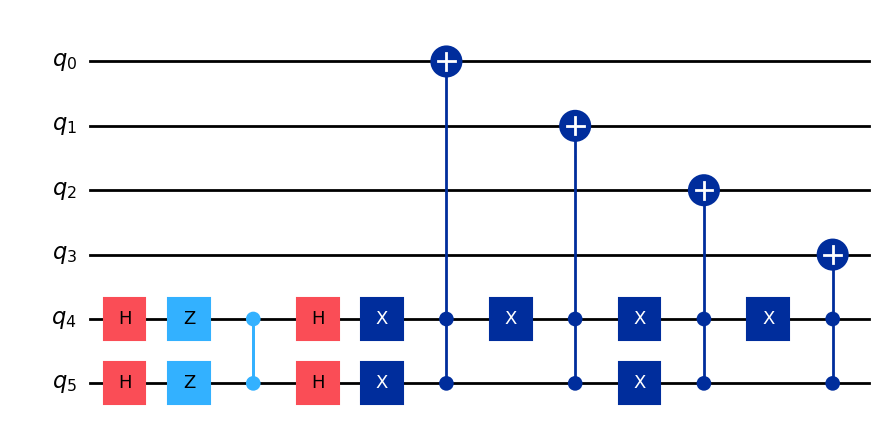

In [135]:
# Build a step ciruit

# circuit needs 6 qubits, 4 for the position and 2 for the coin
one_step_circuit = QuantumCircuit(6, name=" ONE STEP")
step_operator(one_step_circuit)

one_step_circuit.to_instruction()
one_step_circuit.draw("mpl")

We'll also need the inverse of a "step" for multiple reasons. We use the qiskit built in function for this.

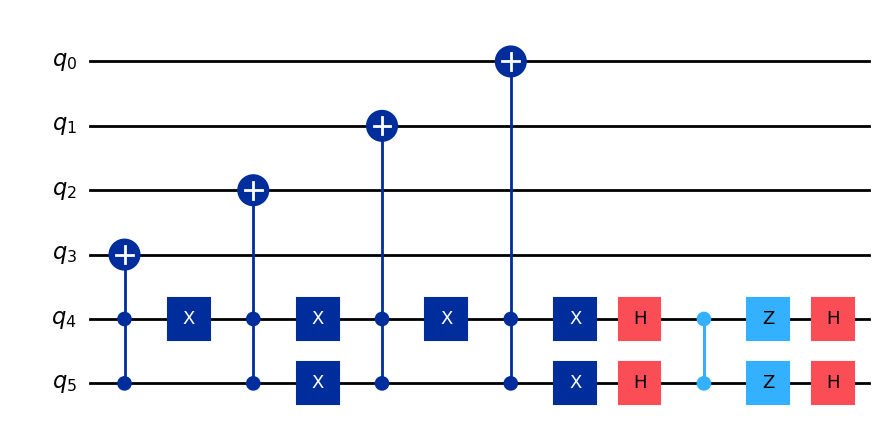

In [136]:
# Draw the inverse-step circuit
inv_step = one_step_circuit.inverse()
inv_step.draw("mpl")

Now, let's wrap these as gates for use in a larger walk algorithm.

In [137]:
# Construct Controlled-Step gates

# Add a control qubit to the circuit and inverse
cont_one_step = one_step_circuit.control()
inv_cont_one_step = inv_step.control()   

# Wrap the controlled circuits as a "gate" for larger circuit display
cont_one_step_gate = cont_one_step.to_instruction(label='One Step')
inv_cont_one_step_gate = inv_cont_one_step.to_instruction(label='Inv Step')

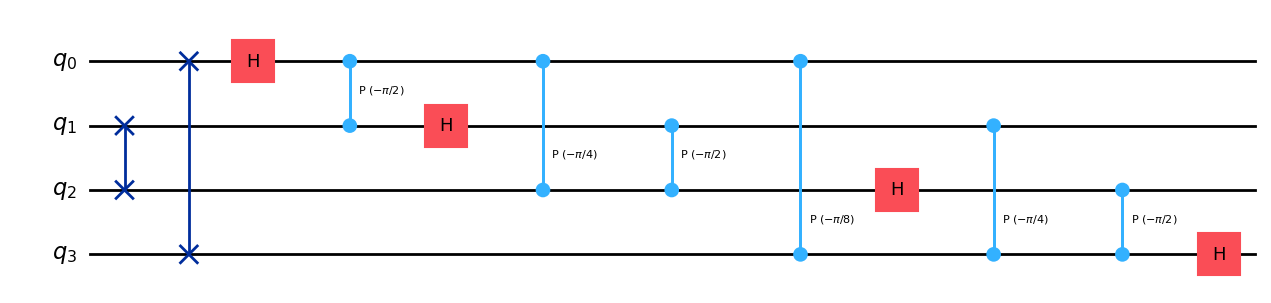

In [138]:
# Construct QFT gates

# Use qiskit's built in QFT function to build these gates
qft_gate = QFT(4, inverse=False).to_instruction(label='QFT')
inv_qft_gate = QFT(4, inverse=True).to_instruction(label='~QFT')

# Inspect the constructed circut
QFT(4, inverse=True).decompose().draw('mpl')

Next we need to construct the circuits for step 2 of the algorithm: Reflecting through _|B>_ and _|U>_. To do so, we'll need a "phase oracle" to mark the desired states. For the sake of being different from the example, we'll randomly determine which states are being marked.

In [139]:
# create function to randomly determine the marked states to find

def get_rand_marks(num_nodes):
    """
    Given a number of nodes to mark, will return a random list to use of that length
    
    :param: num_nodes int - number of nodes to mark on the 4-D hypercube
    :returns: str[]
    """
    
    # Generate a random 4-qubit bstr
    def _get_rand_node():
        rng_bstr = ''
        for _ in range(4):
            rng_bstr += str(randint(0,1))
        return rng_bstr
    
    # validate a reasonable number of marked nodes for 4-qubits
    assert num_nodes > 0
    assert num_nodes <= 5

    # Use a set so repeat nodes aren't counted
    r_bstrs = set()
    while len(r_bstrs) < num_nodes:
        new_r_bstr = _get_rand_node()
        r_bstrs.add(new_r_bstr)

    print(f'Marking nodes: {r_bstrs}')
    return list(r_bstrs)

In [140]:
# Create utility function to transform random bstr into an oracle circuit

def apply_marked_oracle(_qc, bstr):
    """
    Add the oracle function associated with the input bstr to the given quantum circuit
    
    :param: qc QuantumCircuit
    :param: bstr str

    :return: None
    """
    # Apply X gate to any qubits with 0, reverse for qiskit ordering
    for i, b in enumerate(reversed(bstr)):
        if b == '0':
            _qc.x(i)

    # Apply H gate to qubit 3
    _qc.h(3)

    # Apply MCX to qubit 3 with qubits 0-2 as controls
    _qc.mcx([0,1,2], 3)

    # Repeat H and X gates to invert
    _qc.h(3)
    for i, b in enumerate(reversed(bstr)):
        if b == '0':
            _qc.x(i)

In [120]:
# Generate random bstrings and construct an oracle circuit

def construct_oracle_circuit(num_marks):
    """Build and return an oracle gate for a random set of marked nodes"""
    oracle_qc = QuantumCircuit(6)
    random_marks = get_rand_marks(num_marks)
    for rand_mark in random_marks:
        apply_marked_oracle(oracle_qc, rand_mark)
        oracle_qc.barrier()
    
    return oracle_qc

Let's build a random oracle circuit, examine it, and turn it into a gate for the larger walk algorithm.

Marking nodes: {'0111', '0100', '1000'}


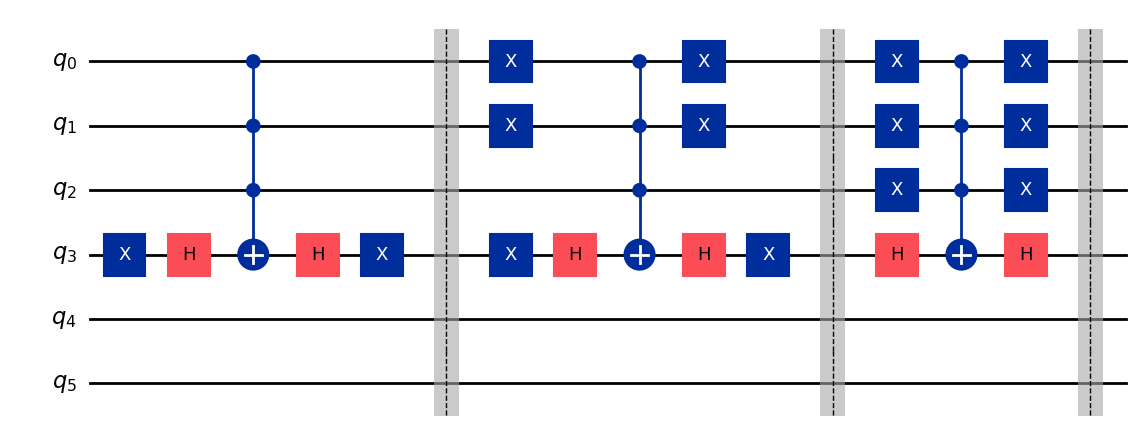

In [141]:
# Build an oracle gate with 3 marked nodes

o_qc = construct_oracle_circuit(3)
oracle_gate = o_qc.to_instruction(label="Phase Oracle")
o_qc.draw("mpl")

Now that we can build an oracle gate, we need to build a phase estimation gate. First, let's build a utility circuit for marking an auxiliary qubit based on if `θ != 0`

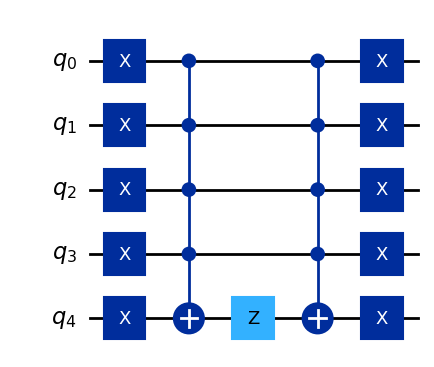

In [142]:
# Build auxiliary qubit marking circuit

# Initiliaze qc with 5 qubits, 4 input + 1 auxiliary
mark_aux_qc = QuantumCircuit(5, name=' mark aux')
# Apply X gate to all qubits
mark_aux_qc.x(range(5))
# Apply MCX to aux using all inputs as control
mark_aux_qc.mcx(list(range(4)), 4)
# Apply Z gate to aux qubit
mark_aux_qc.z(4)
# Invert MCX and X gates
mark_aux_qc.mcx(list(range(4)), 4)
mark_aux_qc.x(range(5))

mark_aux_gate = mark_aux_qc.to_instruction()
mark_aux_qc.draw("mpl")

Now we have all the pieces to build a phase estimation circuit

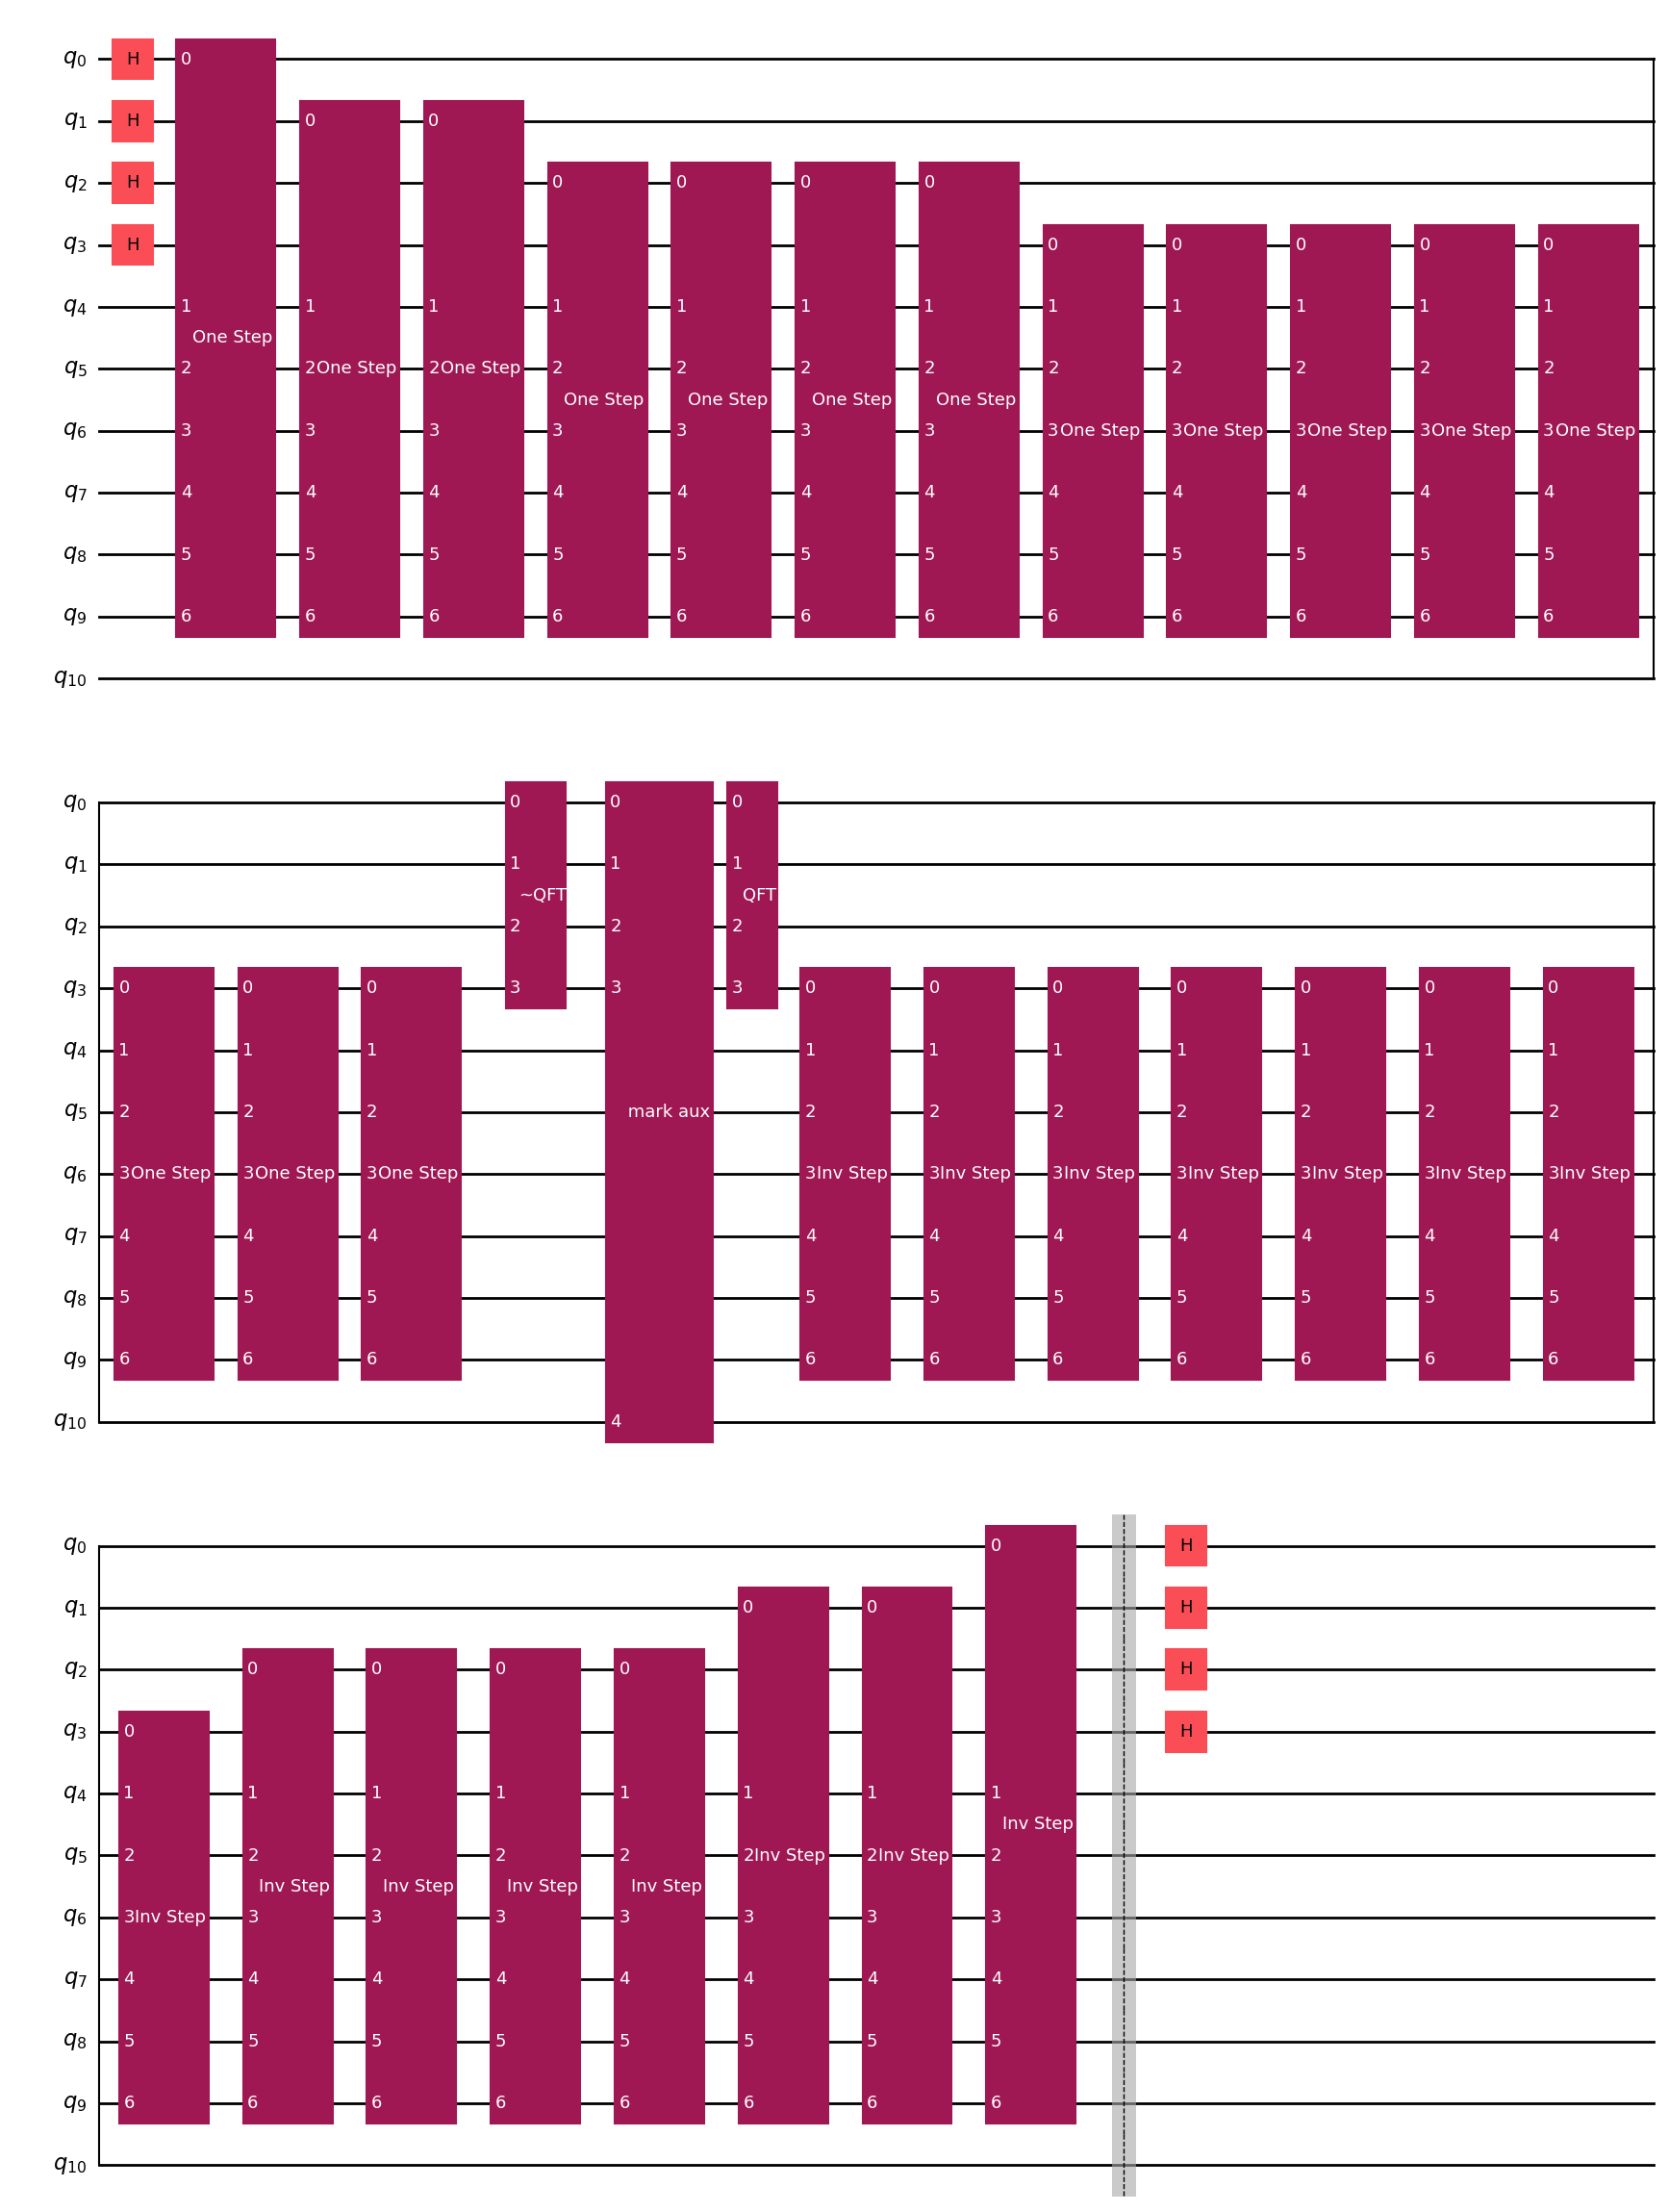

In [143]:
# Build a phase estimation circuit

# Initialize the quantum circuit with 11 qubits:
#   - 4 theta qubits
#   - 6 walk qubits
#   - 1 auxiliary qubit
qpe_qc = QuantumCircuit(11, name=" phase estimation")

# Start by putting theta qubits into uniform superposition
qpe_qc.h(range(4))

# Apply steps in increasing amounts to each theta qubit
for i in range(4):
    i_cnt = 2**i
    for j in range(i_cnt):
        # Use qubit i as control for performing a step
        qpe_qc.append(cont_one_step_gate, [i] + list(range(4, 10)))

# Apply ~QFT
qpe_qc.append(inv_qft_gate, list(range(4)))

# Mark all angles theta that are not 0 with an auxiliary qubit
qpe_qc.append(mark_aux_gate, list(range(4))+[10])

# Reverse phase estimation
qpe_qc.append(qft_gate, list(range(4)))

for i in reversed(list(range(4))):
    i_cnt = 2**i
    for j in range(i_cnt):
        qpe_qc.append(inv_cont_one_step_gate, [i] + list(range(4, 10)))

# Apply a barrier for better visualization
qpe_qc.barrier()
qpe_qc.h(range(4))

# Wrap the full phase estimation circuit into a gate
qpe_gate = qpe_qc.to_instruction(label="Phase Estimation")
qpe_qc.draw("mpl")

Now that we have our oracle gate and phase estimation gate, we can build the circuit for a full quantum walk search algorithm. Let's confirm that our results match the marked nodes.

In [124]:
# Calculate number of iterations based on M = 3
eps = 3/(2**4)
num_i = math.floor(1/math.sqrt(eps))
print(f'Walk requires {num_i} iterations')

Walk requires 2 iterations


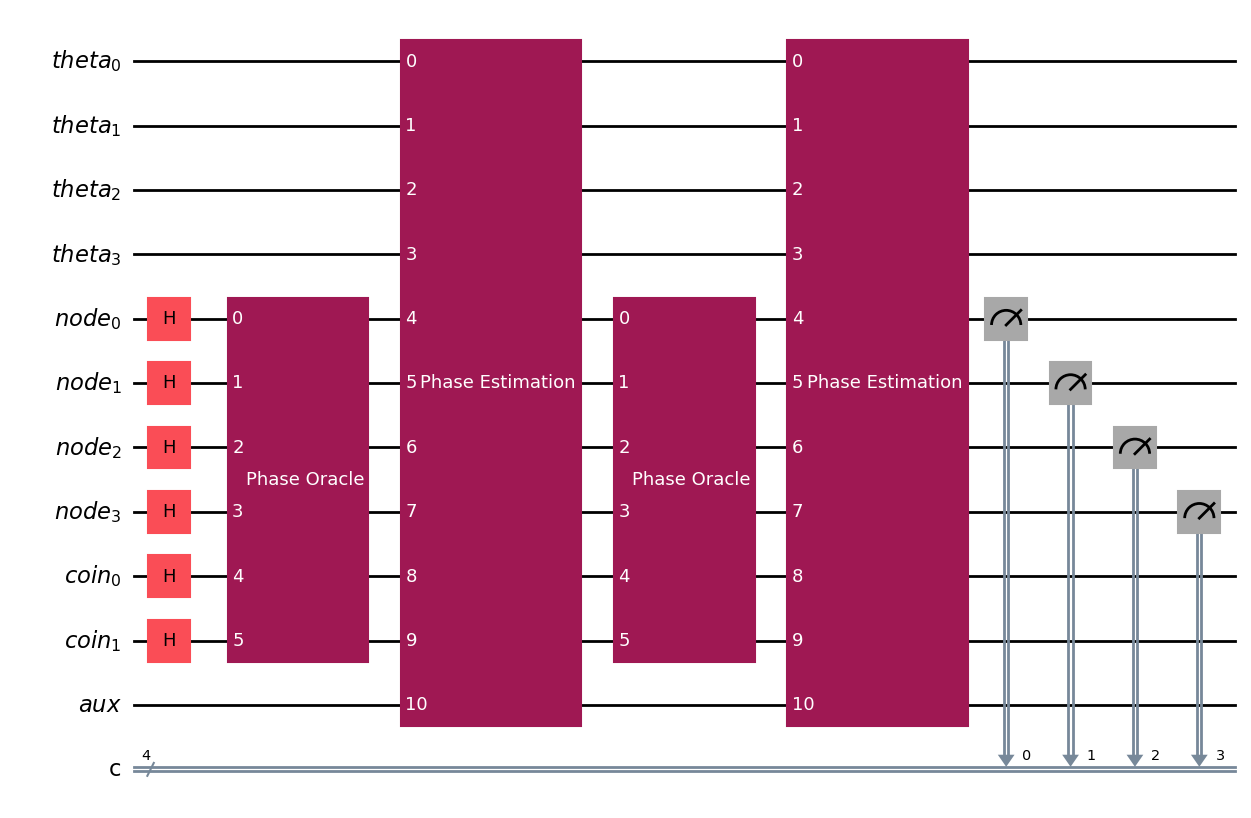

In [144]:
# Build the full quantum walk search algorithm

# Establish the different registers in use and combine into a single circuit
theta_qr = QuantumRegister(4, 'theta')
node_qr = QuantumRegister(4, 'node')
coin_qr =QuantumRegister(2, 'coin')
aux_qr = QuantumRegister(1, 'aux')
creg = ClassicalRegister(4, 'c')

walk_circuit = QuantumCircuit(theta_qr, node_qr, coin_qr, aux_qr, creg)

# Put the node and coin registers into a uniform superposition
walk_circuit.h(range(4, 10))

# Apply the oracle and phase estimation gates num_i times
for i in range(num_i):
    # Oracle is applied to node and coin qubits
    walk_circuit.append(oracle_gate, range(4, 10))
    # Phase estimation gate uses all quantum registers
    walk_circuit.append(qpe_gate, range(11))

# Measure node qubits to classical register
for i in range(4):
    walk_circuit.measure(node_qr[i], creg[i])

walk_circuit.draw("mpl")

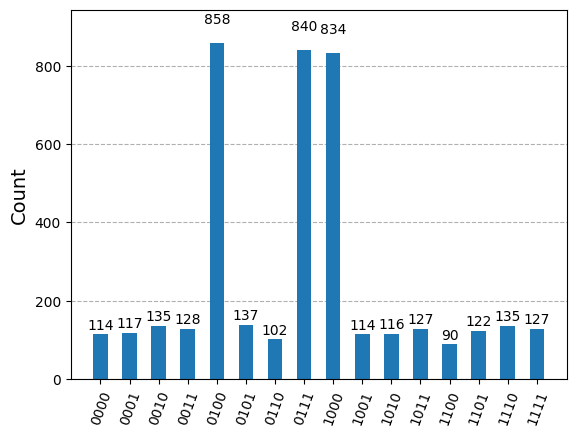

In [149]:
# Sample the results on a simulator and plot the results

transp_walk = transpile(walk_circuit, sampler)
results = sampler.run([transp_walk], shots=4096).result()
plot_histogram(results.get_counts())

Indeed, the most likely measurement are the nodes that we marked randomly!